# 01 — Dữ liệu và trực quan
Chọn kernel đã cài dependencies. Đọc cùng `.env` với terminal/`run_all`.
Chép dataset theo `data/README.md` trước khi chạy. Notebook kiểm tra, không chia lại hay sửa dữ liệu gốc.


Cấu hình mặc định mới: 336px, no TTA, catalog_grouped, relative conformal, nearest-ratio, joint extra-development risk 2%. Restart kernel sau khi đổi .env để tránh giữ cấu hình cũ.


## 1. Nạp các chức năng dùng chung

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
nb_dir = Path.cwd() if (Path.cwd() / 'notebook_utils.py').is_file() else Path.cwd() / 'notebooks'
assert (nb_dir / 'notebook_utils.py').is_file(), 'Mở notebook từ thư mục dự án hoặc notebooks.'
sys.path.insert(0, str(nb_dir.resolve()))
from notebook_utils import validate_dataset, show_table

## 2. Kiểm tra dữ liệu theo cấu hình chung
Kiểm tra hash ảnh, các phiên chụp độc lập và split đã chốt trong dataset.

In [2]:
run = validate_dataset()

Đang chạy dataset-info (configured)...


## 3. Đếm ảnh và phiên chụp
Known dùng cho train/support/calib/test. Unknown chính và unknown bổ sung dùng cho đánh giá riêng.

In [3]:
statistics = run.dataset_statistics()
show_table([r for r in statistics if r['pool'] != '_extra_unknown'])

known: 17 lớp, 9,924 ảnh
unknown: 7 lớp, 4,200 ảnh
_extra_unknown: 38 lớp, 21,202 ảnh


pool,class_name,n_images,n_sessions,train,validation,support,calib,test
known,Bắp cải trắng,600,12,203,149,2,103,31
known,Bắp ngô,600,24,193,188,2,27,190
known,Chanh màu cam,597,15,182,22,2,213,122
known,Cà chua bi vàng,600,12,207,104,2,106,107
known,Cà chua hồng,600,19,116,101,2,36,234
known,Cà chua tim bò,600,11,143,106,2,137,112
known,Cà rốt,600,9,136,94,2,93,185
known,Dưa hấu dài,331,31,147,52,2,52,60
known,Hành tây tím,597,9,156,95,2,88,86
known,Rau xà lách xanh,600,23,283,79,2,54,149


## 4. Vẽ phân bố các lớp

known: 17 lớp, 9,924 ảnh
unknown: 7 lớp, 4,200 ảnh
_extra_unknown: 38 lớp, 21,202 ảnh


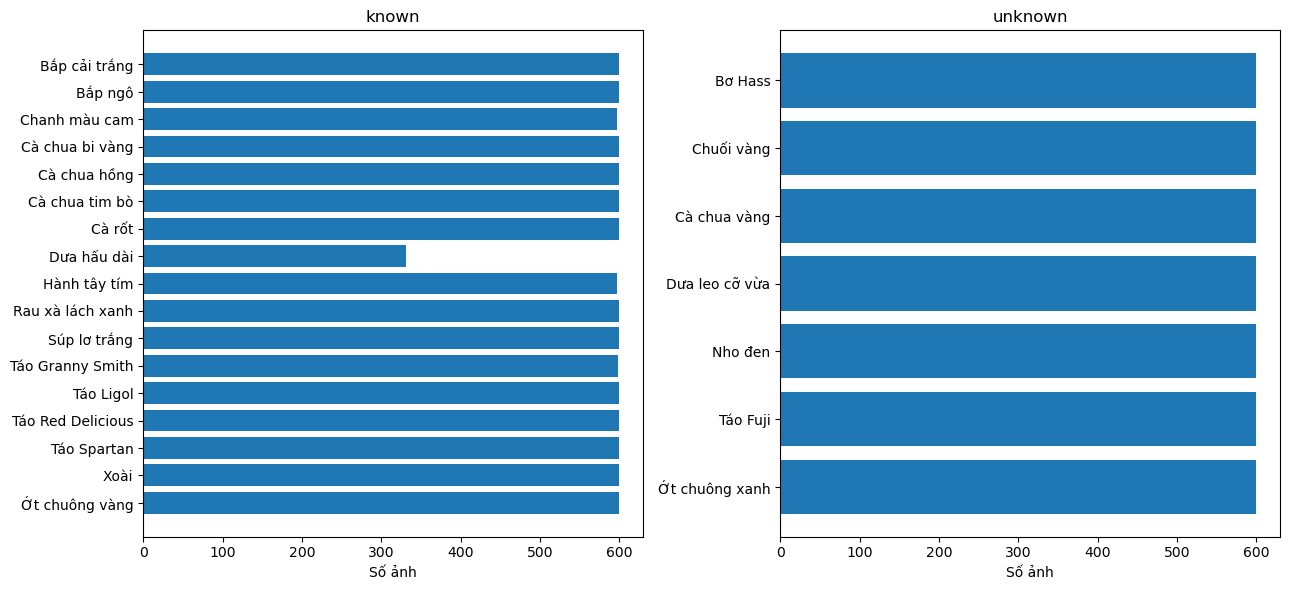

In [4]:
run.plot_distribution()

## 5. Xem mẫu known

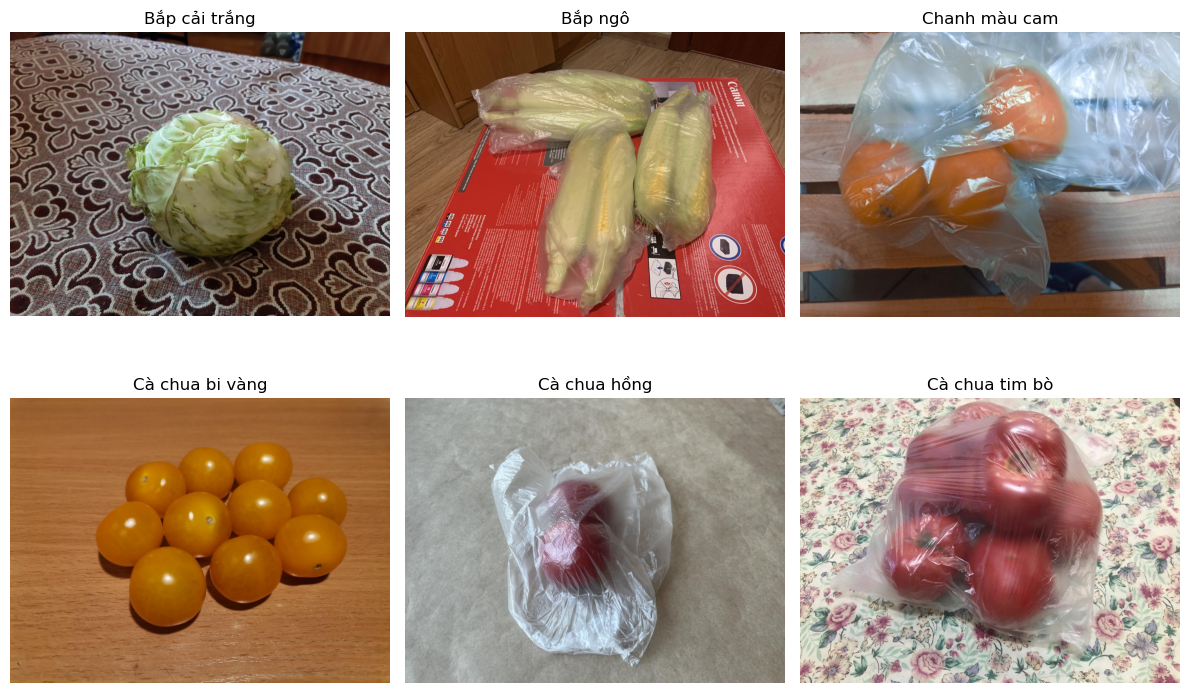

In [5]:
run.show_images('known')

## 6. Xem mẫu unknown chính

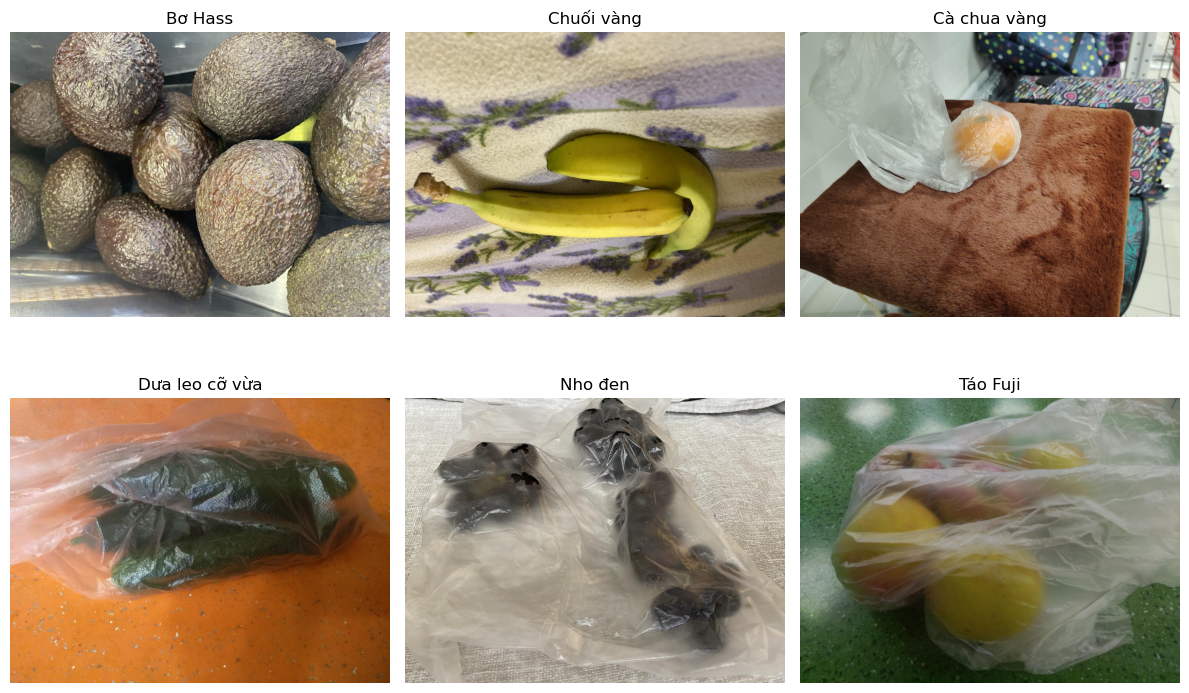

In [6]:
run.show_images('unknown')

## 7. Xem mẫu unknown bổ sung
Các lớp này chưa được đăng ký vào danh mục của model hiện tại.

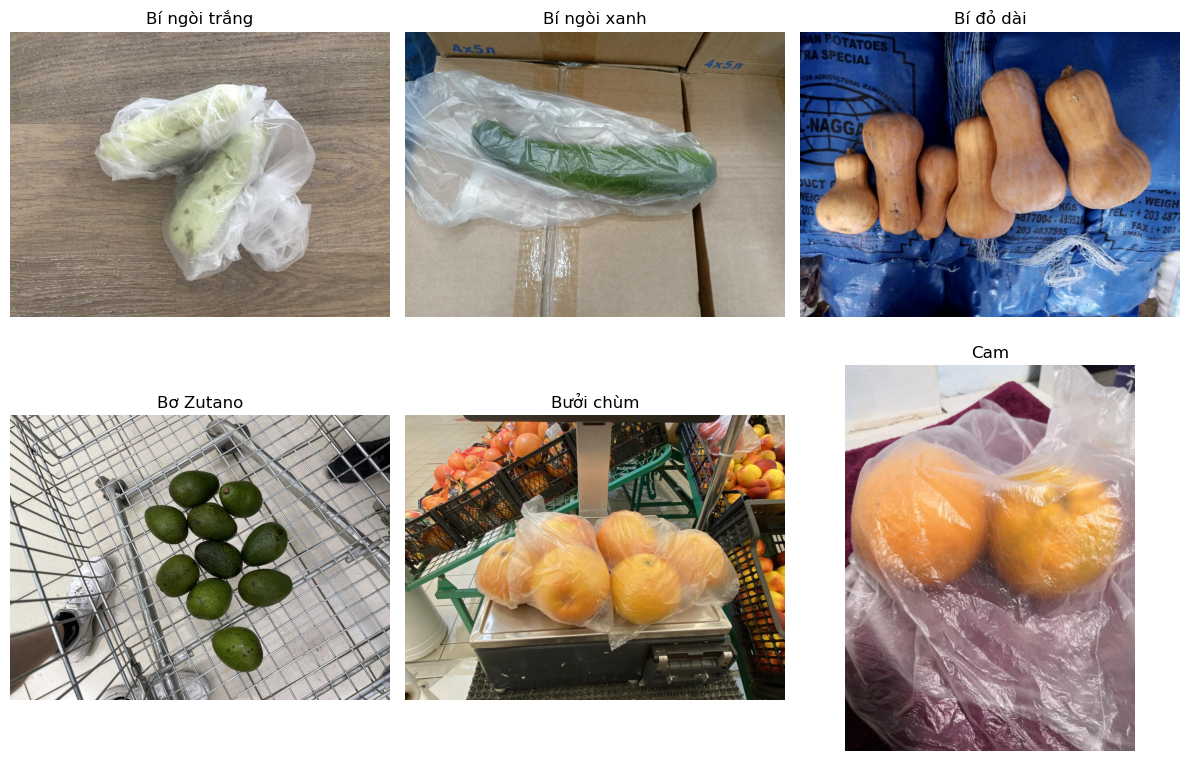

In [7]:
run.show_images('_extra_unknown')

Tiếp theo: **02_train.ipynb**. Có thể mở notebook tiếp theo bằng kernel khác.